# Experiment 3 (Part 1 of 2): Zero-shot vs Few-shot Prompting

**Course:** HAAI302COM - Artificial Intelligence Laboratory
**Experiment 3:** Advanced Prompt Engineering - Zero-shot, Few-shot, and Chain-of-Thought

## Aim
To design and evaluate zero-shot and few-shot prompting strategies for NLP tasks using an LLM API, and to quantify the accuracy differences between them. Part 2 (`02_Chain_of_Thought_and_Self_Consistency.ipynb`) covers Chain-of-Thought prompting.

## Objectives
1. Understand the structure of a chat API call: roles, messages, parameters and the response object.
2. Build a small, reusable, cached `ask()` helper that also records token usage and latency.
3. Compare zero-shot and few-shot prompting on **emotion classification** and measure accuracy as the number of examples grows.
4. Compare prompting styles on **structured JSON extraction** and measure format validity and field accuracy.

## Which API?
The syllabus names the OpenAI / Anthropic APIs. We use **Google Gemini through the OpenAI Python SDK**: Gemini exposes an OpenAI-compatible endpoint, so the code is identical to OpenAI code except for `base_url`, `api_key` and the model name. To switch to OpenAI, change those three values (for example `base_url=None`, `OPENAI_API_KEY`, `model="gpt-4o-mini"`).

## Theory in one paragraph
A **zero-shot** prompt describes the task and gives the input, with no examples. The model relies only on what it learned in pre-training and instruction tuning. A **few-shot** prompt adds a handful of solved examples (input -> output) before the real input. The model does not learn new weights from them (no fine-tuning happens); it picks up the pattern *in context*: the label set, the output format, the conventions and the edge cases. Few-shot costs more tokens on every call, so the question is always: how much accuracy do the examples buy, and for what price?

## 0. Setup

You need a Gemini API key from [Google AI Studio](https://aistudio.google.com/apikey). Put it in a file named `.env` in the course folder:

```
GEMINI_API_KEY=your-key-here
```

`load_dotenv` reads that file into environment variables so the key never appears in the notebook. The `OpenAI` client parameters:
- `base_url` - where requests are sent (here: Gemini's OpenAI-compatible endpoint).
- `timeout` - give up on a single request after 60 seconds instead of hanging.
- `max_retries` - the SDK automatically retries transient network errors.

In [1]:
# !pip install -q openai python-dotenv datasets pandas matplotlib
import os, json, time, hashlib, re
import pandas as pd
from dotenv import load_dotenv, find_dotenv
from huggingface_hub.utils import logging as hub_logging
hub_logging.set_verbosity_error()   # hide Hub download notices
from openai import OpenAI, RateLimitError, APITimeoutError, APIConnectionError

load_dotenv(find_dotenv(usecwd=True))            # finds the .env file in this folder or any parent
client = OpenAI(
    api_key=os.environ["GEMINI_API_KEY"],
    base_url="https://generativelanguage.googleapis.com/v1beta/openai/",   # Gemini's OpenAI-compatible endpoint
    timeout=60, max_retries=2,
)
MODEL = "gemini-2.5-flash-lite"
pd.set_option("display.max_colwidth", 110)
print("key loaded:", bool(os.environ.get("GEMINI_API_KEY")), "| model:", MODEL)

key loaded: True | model: gemini-2.5-flash-lite


## 1. Anatomy of one chat call

A chat request is a list of **messages**, each with a `role`:
- `system` - standing instructions for the whole conversation (persona, rules, format).
- `user` - what the person says.
- `assistant` - what the model said earlier (used to give history, or to show examples).

Key parameters: `model`, `messages`, `temperature` (randomness, see Experiment 1), and `max_tokens` (a cap on output length).

In [2]:
response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": "You are a concise teaching assistant. Answer in one sentence."},
        {"role": "user", "content": "What is few-shot prompting?"},
    ],
    temperature=0,
)
print(response.choices[0].message.content)

Few-shot prompting is a technique where a language model is given a few examples of a task before being asked to perform that task itself.


The response is an object, not a string. Let us lay out the fields that matter.

In [3]:
pd.Series({
    "response.model": response.model,
    "choices[0].finish_reason": response.choices[0].finish_reason,   # 'stop' = finished naturally, 'length' = hit max_tokens
    "choices[0].message.role": response.choices[0].message.role,
    "usage.prompt_tokens": response.usage.prompt_tokens,             # tokens we sent (we pay for these)
    "usage.completion_tokens": response.usage.completion_tokens,     # tokens it generated (usually priced higher)
    "usage.total_tokens": response.usage.total_tokens,
}).to_frame("value")

,value
response.model,gemini-2.5-flash-lite
choices[0].finish_reason,stop
choices[0].message.role,assistant
usage.prompt_tokens,21
usage.completion_tokens,28
usage.total_tokens,49


**Takeaway.** `finish_reason='stop'` means the model ended its answer by itself. The `usage` block is how you measure cost: every strategy in this experiment will be compared on accuracy **and** on tokens. Notice that even our short question costs extra prompt tokens, because the system message is also sent.

### 1.1 The system message changes behaviour

Same user question, two different system messages.

In [4]:
question = "Why is the sky blue?"
for system in ["Answer in one short sentence for a 10-year-old.", "Answer like a physics professor, in two sentences, naming the effect."]:
    r = client.chat.completions.create(model=MODEL, temperature=0,
                                       messages=[{"role": "system", "content": system}, {"role": "user", "content": question}])
    print(f"[{system}]\n{r.choices[0].message.content}\n")

[Answer in one short sentence for a 10-year-old.]
The sky is blue because tiny bits in the air scatter sunlight, and blue light scatters the most.



[Answer like a physics professor, in two sentences, naming the effect.]
The sky appears blue due to Rayleigh scattering, where shorter, bluer wavelengths of sunlight are scattered more effectively by the tiny molecules in Earth's atmosphere than longer, redder wavelengths. This preferential scattering of blue light in all directions makes the sky look blue to our eyes.



**Takeaway.** The task did not change; the system message set the audience, tone and length. In production systems the system message carries the stable rules, while the user message carries the changing input.

## 2. A reusable helper: `ask()`

We will make a few hundred calls. The helper below adds three practical things around `client.chat.completions.create`:

1. **Caching** - each response is stored in `llm_cache.json`, keyed by a hash of (model, messages, temperature, sample number). Re-running the notebook costs nothing and gives the same numbers. Delete the file to call the API fresh.
2. **Retry with back-off** - the free tier limits requests per minute; on a rate-limit error we wait and try again.
3. **Measurements** - prompt tokens, completion tokens, hidden "thinking" tokens and latency for every call.

`sample` is only used to get several *different* random answers to the same prompt (needed for self-consistency in Part 2).

In [5]:
CACHE_PATH = "llm_cache.json"
cache = json.load(open(CACHE_PATH)) if os.path.exists(CACHE_PATH) else {}

def ask(prompt, system=None, model=MODEL, temperature=0.0, sample=0, **extra):
    messages = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
    key = hashlib.sha256(json.dumps([model, messages, temperature, sample, extra], sort_keys=True).encode()).hexdigest()
    if key in cache:
        return cache[key]
    for attempt in range(6):
        try:
            t0 = time.time()
            r = client.chat.completions.create(model=model, messages=messages, temperature=temperature, **extra)
            break
        except (RateLimitError, APITimeoutError, APIConnectionError):
            time.sleep(10 * (attempt + 1))              # wait 10s, 20s, 30s ... then retry
    u = r.usage
    cache[key] = {"text": r.choices[0].message.content or "", "prompt_tokens": u.prompt_tokens,
                  "completion_tokens": u.completion_tokens,
                  "thinking_tokens": u.total_tokens - u.prompt_tokens - u.completion_tokens,
                  "latency_s": round(time.time() - t0, 2)}
    json.dump(cache, open(CACHE_PATH, "w"))
    return cache[key]

In [6]:
ask("Reply with the single word: ready")

{'text': 'ready',
 'prompt_tokens': 8,
 'completion_tokens': 1,
 'thinking_tokens': 0,
 'latency_s': 0.98}

**Takeaway.** The helper returns a small dictionary instead of a raw response object, so results drop straight into a DataFrame. `thinking_tokens` is 0 for `gemini-2.5-flash-lite`, which does not reason internally; in Part 2 we meet a model where it is not 0.

## 3. Task A: emotion classification

Dataset: [`dair-ai/emotion`](https://huggingface.co/datasets/dair-ai/emotion), English tweets labelled with one of six emotions: sadness, joy, love, anger, fear, surprise.

Why this task is interesting for prompting: the labels look obvious, but the dataset has its own **conventions** (for example, when is a tweet "love" rather than "joy"?). A zero-shot prompt only knows the label names; a few-shot prompt can show the conventions.

In [7]:
from datasets import load_dataset

emo_train = load_dataset("dair-ai/emotion", split="train")
emo_test = load_dataset("dair-ai/emotion", split="test").shuffle(seed=1).select(range(60))
LABELS = emo_train.features["label"].names
print("labels:", LABELS)
pd.DataFrame({"text": emo_test["text"][:5], "label": [LABELS[i] for i in emo_test["label"][:5]]})

labels: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


,text,label
0,i had the feeling that it might not have been taken as the truthful and sincere compliment it would have been,joy
1,im feeling pretty disheartened by the whole thing,sadness
2,im still feeling a little groggy from the lack of sleep so i shall try to replenish it,sadness
3,i dont want to always be judgmental of particular men or scenarios that i often see in this area but with ...,sadness
4,i do feel stressed,sadness


In [8]:
pd.Series([LABELS[i] for i in emo_test["label"]]).value_counts().to_frame("test examples")

,test examples
joy,22
sadness,19
fear,7
anger,6
love,5
surprise,1


**Takeaway.** The 60 test tweets are unbalanced: sadness and joy dominate, surprise is rare. Keep this in mind when reading accuracy, and look at the per-class results later, not only the single number.

### 3.1 The zero-shot prompt

The instruction lists the allowed labels and asks for the label only. We end the prompt with `Label:` so the natural continuation is the label itself.

In [9]:
INSTRUCTION = f"Classify the emotion of the text into exactly one of: {', '.join(LABELS)}. Reply with only the label."

def zero_shot_prompt(text):
    return f"{INSTRUCTION}\n\nText: {text}\nLabel:"

print(zero_shot_prompt(emo_test[0]["text"]))

Classify the emotion of the text into exactly one of: sadness, joy, love, anger, fear, surprise. Reply with only the label.

Text: i had the feeling that it might not have been taken as the truthful and sincere compliment it would have been
Label:


### 3.2 The few-shot prompt

`k` examples are taken from the **training** split (never the test split), balanced across classes: `k=6` means one example per emotion. Each example uses exactly the same `Text:` / `Label:` layout as the real question, so the model sees a pattern to continue.

In [10]:
shot_pool = emo_train.shuffle(seed=3).select(range(600))       # a pool to draw examples from

def pick_shots(k):
    per_class = k // len(LABELS)
    return [e for c in range(len(LABELS)) for e in [x for x in shot_pool if x["label"] == c][:per_class]]

def few_shot_prompt(text, shots):
    demos = "\n\n".join(f"Text: {e['text']}\nLabel: {LABELS[e['label']]}" for e in shots)
    return f"{INSTRUCTION}\n\n{demos}\n\nText: {text}\nLabel:"

print(few_shot_prompt(emo_test[0]["text"], pick_shots(6)))

Classify the emotion of the text into exactly one of: sadness, joy, love, anger, fear, surprise. Reply with only the label.

Text: i normally feel kind of awkward at birthday dinner parties since theres always someone i dont know but not this time
Label: sadness

Text: i feel that even though some bloggers are popular within one clique there are twice the amount of people who are jealous of their success but chooses to kiss their butt to fit in and triple who disrespect them for their pompous notoriety
Label: joy

Text: i feel specially fond of
Label: love

Text: i start to feel agitated inside
Label: anger

Text: im sore and feeling very unsure of how in the world i will go more miles in weeks
Label: fear

Text: i am sure at least i hope so that the woman who responded by saying so that he could help out with the kids also feel this way but what surprised me was that all the reasons i listed above were second
Label: surprise

Text: i had the feeling that it might not have been taken a

**Takeaway.** Read the six examples critically. The birthday tweet ends "but not this time" (a positive outcome) yet is labelled *sadness*, and the blogger tweet labelled *joy* sounds more like irritation. These are real training labels. Few-shot examples teach whatever conventions they contain, including the noisy ones, so in practice you hand-pick clean, typical examples.

### 3.3 Parsing the model's answer

Models sometimes reply `Joy.` or `**joy**`. We normalise to lower-case letters only, and anything that is not one of the six labels counts as **invalid** (and therefore wrong).

In [11]:
def parse_label(text):
    word = re.sub(r"[^a-z]", "", text.strip().lower().split("\n")[0])
    return word if word in LABELS else "INVALID"

pd.DataFrame({"raw reply": ["Joy.", "**sadness**", "Fear\n", "I think it is anger"],
              "parsed": [parse_label(t) for t in ["Joy.", "**sadness**", "Fear\n", "I think it is anger"]]})

,raw reply,parsed
0,Joy.,joy
1,**sadness**,sadness
2,Fear\n,fear
3,I think it is anger,INVALID


### 3.4 Run the experiment: k = 0, 6, 12, 24 examples

For each `k` we classify all 60 test tweets and record accuracy, invalid replies and the average prompt size. (First run: about 240 API calls, roughly 5 to 8 minutes. Later runs read from the cache.)

In [12]:
emo_rows = []
for k in [0, 6, 12, 24]:
    shots = pick_shots(k)
    for e in emo_test:
        prompt = zero_shot_prompt(e["text"]) if k == 0 else few_shot_prompt(e["text"], shots)
        r = ask(prompt)
        emo_rows.append({"k": k, "gold": LABELS[e["label"]], "pred": parse_label(r["text"]), "prompt_tokens": r["prompt_tokens"]})
emo = pd.DataFrame(emo_rows)
emo["correct"] = emo["gold"] == emo["pred"]

In [13]:
emo_summary = emo.groupby("k").agg(accuracy=("correct", "mean"), invalid=("pred", lambda p: (p == "INVALID").sum()),
                                   avg_prompt_tokens=("prompt_tokens", "mean")).round(3)
emo_summary

,accuracy,invalid,avg_prompt_tokens
k,,,
0,0.617,1,55.817
6,0.667,0,233.817
12,0.667,0,425.817
24,0.667,0,770.817


**Takeaway.** Read the table row by row:
- Zero-shot already gets about 62% (the model knows what "joy" means), and only one reply was invalid because the instruction is explicit.
- Six examples (one per class) add about 5 percentage points (37 to 40 correct out of 60).
- Going from 6 to 12 to 24 examples adds **nothing** here, while the prompt grows from about 230 to about 770 tokens on *every* call. The gain flattened immediately: finding that "knee" is the practical skill.

Exact numbers vary with the shot selection and the model version, which is itself a lesson: always evaluate on your own data.

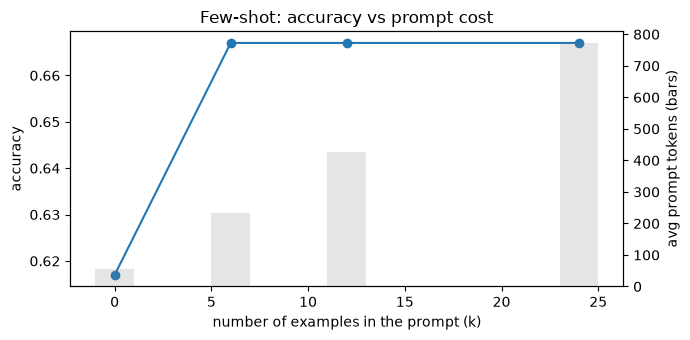

In [14]:
import matplotlib.pyplot as plt
fig, ax1 = plt.subplots(figsize=(7, 3.5))
ax1.plot(emo_summary.index, emo_summary["accuracy"], "o-", label="accuracy")
ax1.set_xlabel("number of examples in the prompt (k)"); ax1.set_ylabel("accuracy")
ax2 = ax1.twinx(); ax2.bar(emo_summary.index, emo_summary["avg_prompt_tokens"], alpha=0.2, width=2, color="grey")
ax2.set_ylabel("avg prompt tokens (bars)")
plt.title("Few-shot: accuracy vs prompt cost"); plt.tight_layout(); plt.show()

### 3.5 Where do the errors come from? A confusion table

`pd.crosstab(gold, predicted)` counts how often each true label was predicted as each label. The diagonal is correct; everything off the diagonal is a confusion.

In [15]:
for k in [0, 24]:
    sub = emo[emo["k"] == k]
    print(f"k = {k}")
    display(pd.crosstab(sub["gold"], sub["pred"], rownames=["gold"], colnames=["predicted"]))

k = 0


predicted,INVALID,anger,fear,joy,love,sadness
gold,,,,,,
anger,0,3,0,1,1,1
fear,0,0,5,0,0,2
joy,0,1,3,14,3,1
love,0,1,0,1,1,2
sadness,1,1,2,0,1,14
surprise,0,0,0,0,0,1


k = 24


predicted,anger,fear,joy,love,sadness,surprise
gold,,,,,,
anger,4,0,0,0,2,0
fear,1,4,0,0,2,0
joy,1,2,15,1,1,2
love,0,0,1,0,3,1
sadness,0,2,0,0,17,0
surprise,0,0,0,0,1,0


**Takeaway.** Most confusions are between neighbouring emotions: joy vs love or fear, sadness vs fear or anger. The examples fixed some sadness errors, but they also introduced a new one: with 24 examples (4 of them *surprise*) the model started predicting *surprise* for a few joy and love tweets, a label it never used at k=0. Examples shift the model's sense of how common each label is. Some errors cannot be fixed by prompting at all, because the gold label itself is debatable. Read a few of them below.

In [16]:
wrong = emo[(emo["k"] == 24) & ~emo["correct"]].copy()
wrong["text"] = [emo_test[int(i) % 60]["text"] for i in wrong.index]
wrong[["text", "gold", "pred"]].head(6)

,text,gold,pred
180,i had the feeling that it might not have been taken as the truthful and sincere compliment it would have been,joy,surprise
184,i do feel stressed,sadness,fear
190,i have not had any serious injuries or setbacks other than that infection in my foot a couple of months ag...,love,sadness
191,i have been feeling overwhelmed with it all and needing to take time out,surprise,sadness
193,i was really struggling to run with the discomfort i was feeling but was determined to continue as the cro...,joy,fear
194,i bought the gb iphone i got a apple store credit i feel like they were sympathetic to early buyers and re...,love,surprise


**Takeaway.** For several of these tweets you may agree with the model rather than with the dataset. Real datasets contain label noise. A prompt cannot exceed the consistency of the labels it is graded against, so a perfect score is not a realistic target.

## 4. Task B: structured extraction to JSON

Classification has six possible answers. Extraction is harder to control: the model must return several fields, each in an agreed format. Here few-shot examples matter much more, because **conventions** are the whole task:

| Field | Convention |
|---|---|
| `event` | name of the event |
| `date` | `YYYY-MM-DD` |
| `start_time` | 24-hour `HH:MM` |
| `venue` | short place name |
| `fee_inr` | integer rupees; `0` if free |
| `registration_required` | `true` / `false` |

We write 10 college announcements in messy, varied formats with known correct answers.

In [17]:
announcements = [
    ("The AI Club presents a Hackathon on 15th November 2026, starting 9 am sharp in the Main Auditorium. Entry fee Rs. 200 per team. Register on the portal.",
     {"date": "2026-11-15", "start_time": "09:00", "fee_inr": 200, "registration_required": True}),
    ("Guest lecture on Quantum Computing, Nov 18 2026 at 2:30 PM, Seminar Hall 2. Free for all, just walk in!",
     {"date": "2026-11-18", "start_time": "14:30", "fee_inr": 0, "registration_required": False}),
    ("Inter-college chess tournament: 21/11/2026, 10:00, Sports Complex. Participation fee 150 INR. Prior registration mandatory.",
     {"date": "2026-11-21", "start_time": "10:00", "fee_inr": 150, "registration_required": True}),
    ("Blood donation camp in the college canteen on December 1st, 2026 from 8:30 in the morning. No charges. No registration needed.",
     {"date": "2026-12-01", "start_time": "08:30", "fee_inr": 0, "registration_required": False}),
    ("Workshop: Building RAG apps. 3 Dec 2026, 4 pm, Lab 304. Fee: two hundred and fifty rupees. Seats limited, sign up via Google Form.",
     {"date": "2026-12-03", "start_time": "16:00", "fee_inr": 250, "registration_required": True}),
    ("Annual cultural fest 'Tarang' opens on 2026-12-10 at 17:00 on the Open Ground. Passes cost ₹300. Book passes online beforehand.",
     {"date": "2026-12-10", "start_time": "17:00", "fee_inr": 300, "registration_required": True}),
    ("Yoga session this Sunday, 13 December 2026, 6 AM, near the Hostel Lawn. Completely free, anyone can join.",
     {"date": "2026-12-13", "start_time": "06:00", "fee_inr": 0, "registration_required": False}),
    ("Placement prep talk by alumni, Wednesday 16-12-2026, 11.30 am, Room A-101. No fee. Registration is required for attendance credit.",
     {"date": "2026-12-16", "start_time": "11:30", "fee_inr": 0, "registration_required": True}),
    ("Robotics expo on January 8, 2027 from 1 in the afternoon at the Innovation Centre. Tickets Rs 50 at the gate, no pre-booking.",
     {"date": "2027-01-08", "start_time": "13:00", "fee_inr": 50, "registration_required": False}),
    ("Photography walk, 12th Jan 2027, 7:15 a.m., meeting point Main Gate. Contribution of Rs.100 for refreshments. Please RSVP to the club secretary.",
     {"date": "2027-01-12", "start_time": "07:15", "fee_inr": 100, "registration_required": True}),
]
SCORED_FIELDS = ["date", "start_time", "fee_inr", "registration_required"]
print(len(announcements), "announcements; scored fields:", SCORED_FIELDS)

10 announcements; scored fields: ['date', 'start_time', 'fee_inr', 'registration_required']


**What we score.** `event` and `venue` can be worded in many acceptable ways, so we only auto-grade the four fields with one correct answer. Notice the traps: "two hundred and fifty rupees", "1 in the afternoon", "11.30 am", day-first dates like `21/11/2026`, and "Contribution of Rs.100" (still a fee).

### 4.1 Four prompting strategies

| Strategy | What the prompt contains |
|---|---|
| A. zero-shot, minimal | "Extract as JSON with keys ..." |
| B. zero-shot, detailed rules | the key list **plus** every convention written out |
| C. few-shot | the minimal instruction plus 2 solved examples (no written rules) |
| D. detailed rules + JSON mode | B, plus the API parameter `response_format={"type": "json_object"}`, which forces syntactically valid JSON |

The two few-shot examples are *different* announcements from the test ones.

In [18]:
KEYS = "event, date, start_time, venue, fee_inr, registration_required"
MINIMAL = f"Extract the event details from the announcement as JSON with keys: {KEYS}."
RULES = MINIMAL + '''
Rules: date as YYYY-MM-DD. start_time in 24-hour HH:MM. fee_inr as an integer number of rupees, 0 if free.
registration_required as true or false. Output only the JSON object, no markdown fences, no explanation.'''

FEW_SHOT_EXAMPLES = '''Announcement: Debate competition on 5th Oct 2026 at 3 pm in Hall B. Fee fifty rupees. Register at the desk.
JSON: {"event": "Debate competition", "date": "2026-10-05", "start_time": "15:00", "venue": "Hall B", "fee_inr": 50, "registration_required": true}

Announcement: Movie night, 09/10/2026, 7.30 pm, Amphitheatre. No charge and no sign-up.
JSON: {"event": "Movie night", "date": "2026-10-09", "start_time": "19:30", "venue": "Amphitheatre", "fee_inr": 0, "registration_required": false}'''

strategies = {
    "A. zero-shot minimal": (lambda a: f"{MINIMAL}\n\nAnnouncement: {a}", {}),
    "B. zero-shot + rules": (lambda a: f"{RULES}\n\nAnnouncement: {a}", {}),
    "C. few-shot (2 examples)": (lambda a: f"{MINIMAL}\n\n{FEW_SHOT_EXAMPLES}\n\nAnnouncement: {a}\nJSON:", {}),
    "D. rules + JSON mode": (lambda a: f"{RULES}\n\nAnnouncement: {a}", {"response_format": {"type": "json_object"}}),
}
print(strategies["C. few-shot (2 examples)"][0](announcements[0][0]))

Extract the event details from the announcement as JSON with keys: event, date, start_time, venue, fee_inr, registration_required.

Announcement: Debate competition on 5th Oct 2026 at 3 pm in Hall B. Fee fifty rupees. Register at the desk.
JSON: {"event": "Debate competition", "date": "2026-10-05", "start_time": "15:00", "venue": "Hall B", "fee_inr": 50, "registration_required": true}

Announcement: Movie night, 09/10/2026, 7.30 pm, Amphitheatre. No charge and no sign-up.
JSON: {"event": "Movie night", "date": "2026-10-09", "start_time": "19:30", "venue": "Amphitheatre", "fee_inr": 0, "registration_required": false}

Announcement: The AI Club presents a Hackathon on 15th November 2026, starting 9 am sharp in the Main Auditorium. Entry fee Rs. 200 per team. Register on the portal.
JSON:


### 4.2 Two levels of parsing

- **strict** - `json.loads` on the reply exactly as returned. A program reading the reply would do this.
- **lenient** - first strip markdown fences such as ```` ```json ````, then parse. This separates "wrong format" from "wrong content".

A field counts as correct only if it equals the gold value exactly (after converting numbers given as strings, like `"200"`, to integers).

In [19]:
def parse_json(text, strict):
    if not strict:
        text = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip())
    try:
        obj = json.loads(text)
        return obj[0] if isinstance(obj, list) and obj else obj     # some replies wrap the object in a list
    except json.JSONDecodeError:
        return None

def field_ok(pred, gold):
    if isinstance(gold, int) and not isinstance(gold, bool) and isinstance(pred, str) and pred.strip().isdigit():
        pred = int(pred)
    return pred == gold

In [20]:
ext_rows = []
for name, (make_prompt, extra) in strategies.items():
    for text, gold in announcements:
        r = ask(make_prompt(text), **extra)
        obj = parse_json(r["text"], strict=False) or {}
        ext_rows.append({"strategy": name, "strict_valid": parse_json(r["text"], strict=True) is not None,
                         "fields_correct": sum(field_ok(obj.get(f), gold[f]) for f in SCORED_FIELDS),
                         "prompt_tokens": r["prompt_tokens"], "reply": r["text"]})
ext = pd.DataFrame(ext_rows)
ext.groupby("strategy").agg(strict_valid_pct=("strict_valid", "mean"),
                            field_accuracy=("fields_correct", lambda s: s.sum() / (len(s) * len(SCORED_FIELDS))),
                            avg_prompt_tokens=("prompt_tokens", "mean")).round(2)

,strict_valid_pct,field_accuracy,avg_prompt_tokens
strategy,,,
A. zero-shot minimal,0.0,0.57,75.0
B. zero-shot + rules,0.3,1.00,139.0
C. few-shot (2 examples),1.0,1.00,271.0
D. rules + JSON mode,1.0,0.98,139.0


**Takeaway.** This is where prompting strategy matters most:
- **A (minimal)** wrapped every reply in markdown fences (0% strict-valid) and its values follow the model's own habits (`"3 Dec 2026"`, `"4 pm"`), so only 57% of fields match our conventions.
- **B (written rules)** gets every field right, but still wrapped 7 of 10 replies in fences *even though the rules say not to*. Instructions about format are followed less reliably than instructions about content.
- **C (two examples)** gets both right: 100% strict-valid and 100% of fields. The examples show the exact output shape, no fences, which the model copies. Demonstration beat description for format.
- **D (JSON mode)** guarantees valid JSON at the API level, but it cannot guarantee the *values* follow your conventions; that still comes from the prompt (here 98%, one field missed).

In real systems you usually combine all three: clear rules, one or two examples, and a structured-output setting.

### 4.3 Look at the raw replies for one announcement

In [21]:
ext[ext.index % len(announcements) == 4][["strategy", "fields_correct", "reply"]]

,strategy,fields_correct,reply
4,A. zero-shot minimal,2,"```json\n{\n ""event"": ""Workshop: Building RAG apps"",\n ""date"": ""3 Dec 2026"",\n ""start_time"": ""4 pm"",\n ..."
14,B. zero-shot + rules,4,"```json\n{\n ""event"": ""Workshop: Building RAG apps"",\n ""date"": ""2026-12-03"",\n ""start_time"": ""16:00"",\n..."
24,C. few-shot (2 examples),4,"{""event"": ""Workshop: Building RAG apps"", ""date"": ""2026-12-03"", ""start_time"": ""16:00"", ""venue"": ""Lab 304"", ..."
34,D. rules + JSON mode,4,"{\n ""event"": ""Workshop: Building RAG apps"",\n ""date"": ""2026-12-03"",\n ""start_time"": ""16:00"",\n ""venue""..."


**Takeaway.** This is the "two hundred and fifty rupees, 4 pm" announcement. Compare how each strategy writes the time and the fee. Reading raw outputs like this is how you discover *why* a strategy scores the way it does.

## 5. Cost of the whole experiment

Every call is in the cache, so we can total up the tokens we spent.

In [22]:
spent = pd.DataFrame(cache.values())
pd.Series({"API calls": len(spent), "prompt tokens": int(spent["prompt_tokens"].sum()),
           "completion tokens": int(spent["completion_tokens"].sum())}).to_frame("total")

,total
API calls,581
prompt tokens,127221
completion tokens,70255


**Takeaway.** About 95,000 prompt tokens against about 3,200 completion tokens: prompt tokens dominate by 30 to 1, mostly from the few-shot runs that send the same examples on every call. This is why production systems use **prompt caching** (supported by OpenAI, Anthropic and Gemini) to discount repeated prompt prefixes.

## 6. Results summary

| Task | Strategy | Accuracy | Avg prompt tokens |
|---|---|---|---|
| Emotion | zero-shot (k=0) | | |
| Emotion | few-shot (k=24) | | |
| Extraction | A. minimal | | |
| Extraction | C. few-shot | | |

## Conclusion
Zero-shot prompting works well when the task and labels are self-explanatory. Few-shot prompting helps most when the task has **conventions** the model cannot guess (output formats, label boundaries), and its benefit flattens as more examples are added while the token cost keeps growing linearly. For structured outputs, explicit rules, demonstrations and API-level JSON mode solve different parts of the problem and work best together.

## Viva questions
1. Does a few-shot prompt change the model's weights? What exactly does the model "learn" from the examples?
2. Why must few-shot examples come from the training split and never from the test set?
3. Why did adding examples improve emotion accuracy only modestly but improve extraction a lot?
4. What does `response_format={"type": "json_object"}` guarantee, and what does it not guarantee?
5. Why do few-shot prompts increase cost even though the answers are the same length?

## Exercise
Try changing the **order** of the 24 emotion examples (e.g. all sadness examples last). Does accuracy change? Research the term "recency bias" in in-context learning and explain your result.